## Project Overview
Flight ticket prices are hard to guess: the same flight can cost a different amount tomorrow. This project develops a machine learning regression system to estimate flight ticket prices from historical flight information, to help customers plan their journey and to help airlines understand which prices the market supports.

## Business Objective
Analyze the provided flight-fare dataset, identify the factors associated with ticket prices (airline, route, duration, stops, date and time), compare multiple regression models, select the best-performing model for prediction, and use it to help customers compare options and plan when and how to travel.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)

In [2]:
raw = pd.read_excel("Flight_Fare.xlsx")
print(raw.shape)
raw.head()

(10683, 11)


,Airline,Date_of_Journey,Source,Destination,Route,Dep_Time,Arrival_Time,Duration,Total_Stops,Additional_Info,Price
0,IndiGo,24/03/2019,Banglore,New Delhi,BLR → DEL,22:20,01:10 22 Mar,2h 50m,non-stop,No info,3897
1,Air India,1/05/2019,Kolkata,Banglore,CCU → IXR → BBI → BLR,05:50,13:15,7h 25m,2 stops,No info,7662
2,Jet Airways,9/06/2019,Delhi,Cochin,DEL → LKO → BOM → COK,09:25,04:25 10 Jun,19h,2 stops,No info,13882
3,IndiGo,12/05/2019,Kolkata,Banglore,CCU → NAG → BLR,18:05,23:30,5h 25m,1 stop,No info,6218
4,IndiGo,01/03/2019,Banglore,New Delhi,BLR → NAG → DEL,16:50,21:35,4h 45m,1 stop,No info,13302


In [3]:
raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10683 entries, 0 to 10682
Data columns (total 11 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   Airline          10683 non-null  object
 1   Date_of_Journey  10683 non-null  object
 2   Source           10683 non-null  object
 3   Destination      10683 non-null  object
 4   Route            10682 non-null  object
 5   Dep_Time         10683 non-null  object
 6   Arrival_Time     10683 non-null  object
 7   Duration         10683 non-null  object
 8   Total_Stops      10682 non-null  object
 9   Additional_Info  10683 non-null  object
 10  Price            10683 non-null  int64 
dtypes: int64(1), object(10)
memory usage: 918.2+ KB


In [4]:
print("Missing values:\n", raw.isnull().sum()[raw.isnull().sum() > 0])
print("\nDuplicate rows:", raw.duplicated().sum())
raw.nunique()

Missing values:
 Route          1
Total_Stops    1
dtype: int64

Duplicate rows: 220


Airline              12
Date_of_Journey      44
Source                5
Destination           6
Route               128
Dep_Time            222
Arrival_Time       1343
Duration            368
Total_Stops           5
Additional_Info      10
Price              1870
dtype: int64

In [5]:
for c in ["Airline", "Source", "Destination", "Total_Stops", "Additional_Info"]:
    print(raw[c].value_counts(dropna=False), "\n")

Airline
Jet Airways                          3849
IndiGo                               2053
Air India                            1752
Multiple carriers                    1196
SpiceJet                              818
Vistara                               479
Air Asia                              319
GoAir                                 194
Multiple carriers Premium economy      13
Jet Airways Business                    6
Vistara Premium economy                 3
Trujet                                  1
Name: count, dtype: int64 

Source
Delhi       4537
Kolkata     2871
Banglore    2197
Mumbai       697
Chennai      381
Name: count, dtype: int64 

Destination
Cochin       4537
Banglore     2871
Delhi        1265
New Delhi     932
Hyderabad     697
Kolkata       381
Name: count, dtype: int64 

Total_Stops
1 stop      5625
non-stop    3491
2 stops     1520
3 stops       45
NaN            1
4 stops        1
Name: count, dtype: int64 

Additional_Info
No info                         83

**Observations:** The dataset has 10,683 flights and 11 columns, all text except Price. One row has missing Route/Total_Stops, 220 rows are duplicates, Destination contains both "Delhi" and "New Delhi", and Additional_Info has inconsistent capitalisation. Date, time and duration columns are stored as text and must be converted.

# Data Cleaning

In [6]:
df = raw.copy()

df = df.dropna().reset_index(drop=True)                 # removes the 1 incomplete row
df = df.drop_duplicates().reset_index(drop=True)        # removes 220 duplicates
print(df.shape)

(10462, 11)


In [7]:
df["Destination"] = df["Destination"].replace({"New Delhi": "Delhi"})
df["Additional_Info"] = df["Additional_Info"].replace({"No Info": "No info"})

In [8]:
df.groupby("Source")["Destination"].nunique()

Source
Banglore    1
Chennai     1
Delhi       1
Kolkata     1
Mumbai      1
Name: Destination, dtype: int64

In [9]:
hours   = df["Duration"].str.extract(r"(\d+)\s*h")[0].astype(float).fillna(0)
minutes = df["Duration"].str.extract(r"(\d+)\s*m")[0].astype(float).fillna(0)
df["duration_mins"] = (hours * 60 + minutes).astype(int)

In [10]:
bad = df[(df["duration_mins"] < 60) & (df["Total_Stops"] != "non-stop")]
print(bad[["Airline", "Source", "Route", "Dep_Time", "Arrival_Time", "Duration", "Total_Stops"]])

        Airline  Source                  Route Dep_Time Arrival_Time Duration  \
6397  Air India  Mumbai  BOM → GOI → PNQ → HYD    16:50        16:55       5m   

     Total_Stops  
6397     2 stops  


In [11]:
df = df.drop(bad.index).reset_index(drop=True)
print(df.shape)

(10461, 12)


**Cleaning decisions:** One incomplete row, 220 duplicate rows and one impossible record (a 2-stop flight with a 5-minute duration) were removed. "New Delhi" was merged into "Delhi" and "No Info" into "No info". Destination is fully determined by Source, so it is redundant.

# Feature Extraction 

In [12]:
# Date of journey (day first: 24/03/2019 = 24 March)
df["Date_of_Journey"] = pd.to_datetime(df["Date_of_Journey"], dayfirst=True)
df["journey_day"]     = df["Date_of_Journey"].dt.day
df["journey_month"]   = df["Date_of_Journey"].dt.month
df["journey_weekday"] = df["Date_of_Journey"].dt.dayofweek      # 0 = Monday

# Departure time
dep = pd.to_datetime(df["Dep_Time"], format="%H:%M")
df["dep_hour"] = dep.dt.hour
df["dep_min"]  = dep.dt.minute

# Arrival time: some values look like "01:10 22 Mar", so keep only the "HH:MM" part
arr = pd.to_datetime(df["Arrival_Time"].str.split(" ").str[0], format="%H:%M")
df["arr_hour"] = arr.dt.hour
df["arr_min"]  = arr.dt.minute

# Stops as a number
df["stops"] = df["Total_Stops"].map({"non-stop": 0, "1 stop": 1, "2 stops": 2, "3 stops": 3, "4 stops": 4})

# Time-of-day slot (for EDA)
df["dep_slot"] = pd.cut(df["dep_hour"], bins=[-1, 5, 11, 17, 21, 23],
                        labels=["Night (0-5)", "Morning (6-11)", "Afternoon (12-17)",
                                "Evening (18-21)", "Late night (22-23)"])

# Log of price (the target is skewed)
df["log_price"] = np.log1p(df["Price"])

df[["journey_day", "journey_month", "dep_hour", "arr_hour", "duration_mins", "stops", "Price"]].head()

,journey_day,journey_month,dep_hour,arr_hour,duration_mins,stops,Price
0,24,3,22,1,170,0,3897
1,1,5,5,13,445,2,7662
2,9,6,9,4,1140,2,13882
3,12,5,18,23,325,1,6218
4,1,3,16,21,285,1,13302


In [13]:
print((df["Route"].str.count("→") == df["stops"] + 1).all())

True


# EDA 

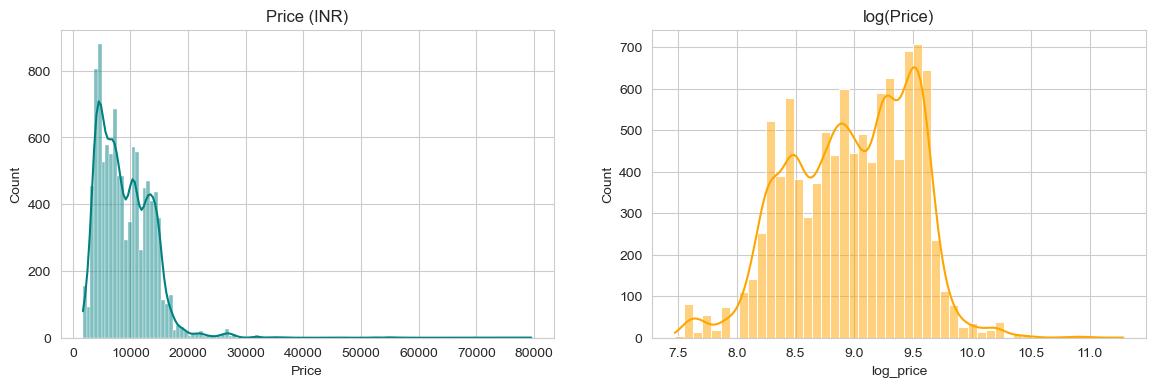

Skewness: 1.86 → -0.23


count    10461.0
mean      9026.0
std       4624.0
min       1759.0
25%       5224.0
50%       8266.0
75%      12341.0
max      79512.0
Name: Price, dtype: float64

In [14]:
# Price Distribution
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
sns.histplot(df["Price"], kde=True, ax=ax[0], color="teal");  ax[0].set_title("Price (INR)")
sns.histplot(df["log_price"], kde=True, ax=ax[1], color="orange"); ax[1].set_title("log(Price)")
plt.show()
print("Skewness:", round(df["Price"].skew(), 2), "→", round(df["log_price"].skew(), 2))
df["Price"].describe().round(0)

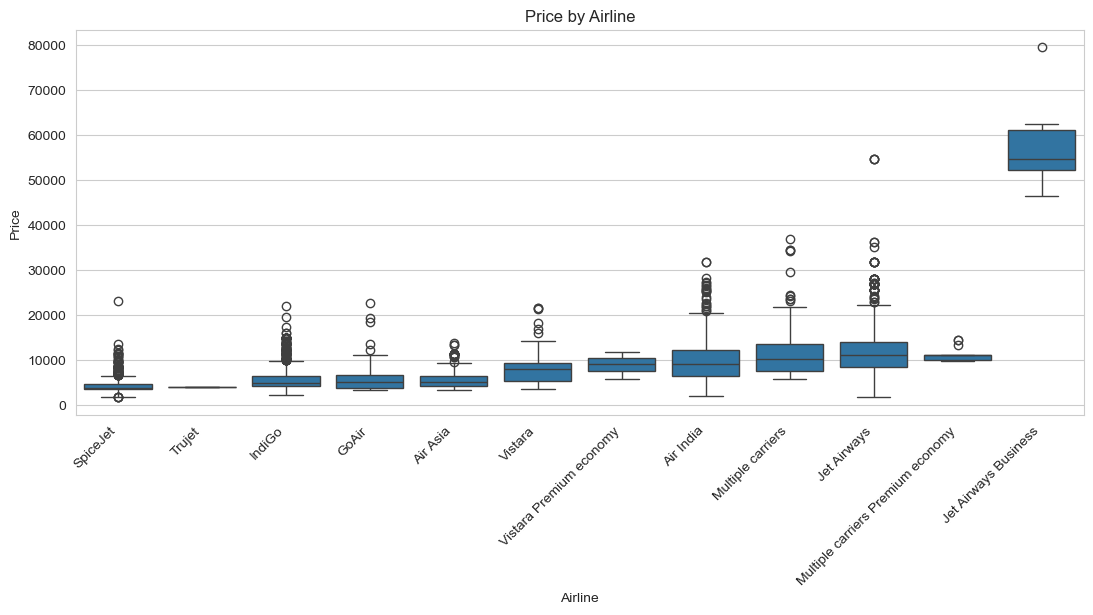

,median,count
Airline,,
SpiceJet,3873.0,815
Trujet,4140.0,1
IndiGo,5000.0,2043
GoAir,5135.0,194
Air Asia,5162.0,319
Vistara,7980.0,478
Vistara Premium economy,9125.0,3
Air India,9292.0,1693
Multiple carriers,10197.0,1196


In [15]:
# Price By Line 
order = df.groupby("Airline")["Price"].median().sort_values().index
plt.figure(figsize=(13, 5))
sns.boxplot(data=df, x="Airline", y="Price", order=order)
plt.xticks(rotation=45, ha="right"); plt.title("Price by Airline")
plt.show()
df.groupby("Airline")["Price"].agg(["median", "count"]).loc[order].round(0)

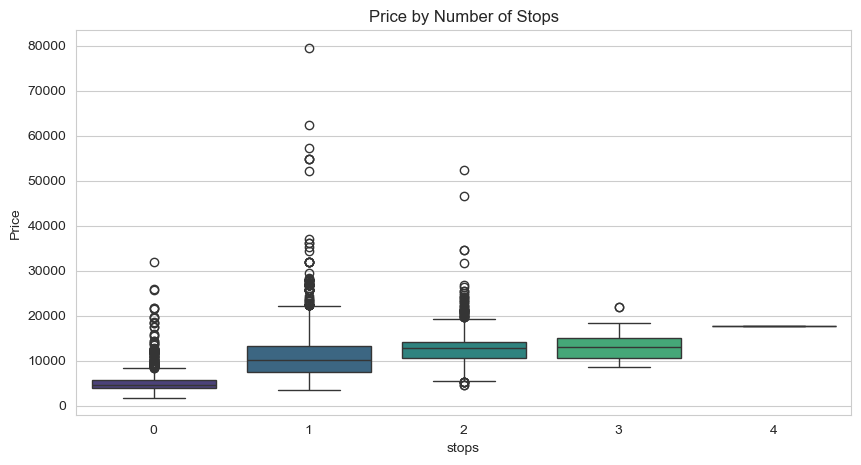

,mean,median,count
stops,,,
0,5019.0,4667.0,3475
1,10594.0,10262.0,5625
2,12758.0,12723.0,1317
3,13261.0,13007.0,43
4,17686.0,17686.0,1


In [16]:
# Price By Number Of Stops
sns.boxplot(data=df, x="stops", y="Price", palette="viridis")
plt.title("Price by Number of Stops"); plt.show()
df.groupby("stops")["Price"].agg(["mean", "median", "count"]).round(0)

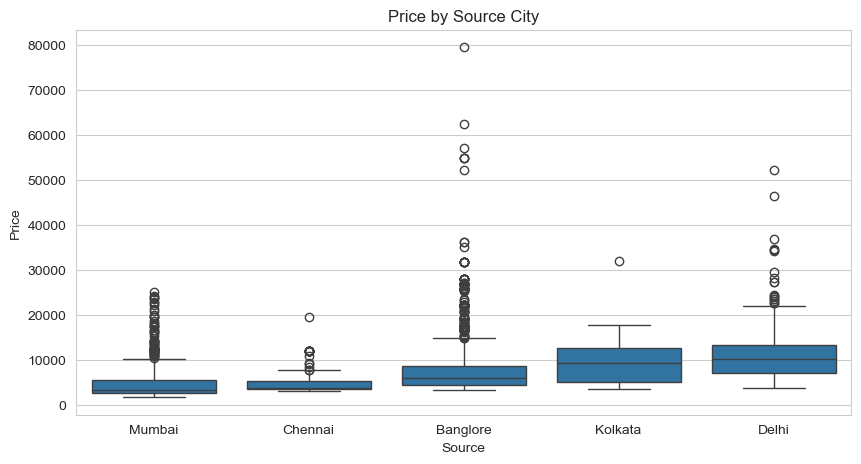

,mean,median,count
Source,,,
Banglore,8023.0,6121.0,2179
Chennai,4790.0,3850.0,381
Delhi,10462.0,10262.0,4345
Kolkata,9143.0,9345.0,2860
Mumbai,5042.0,3276.0,696


In [17]:
# Price By Source Of City 
sns.boxplot(data=df, x="Source", y="Price", order=df.groupby("Source")["Price"].median().sort_values().index)
plt.title("Price by Source City"); plt.show()
df.groupby("Source")["Price"].agg(["mean", "median", "count"]).round(0)

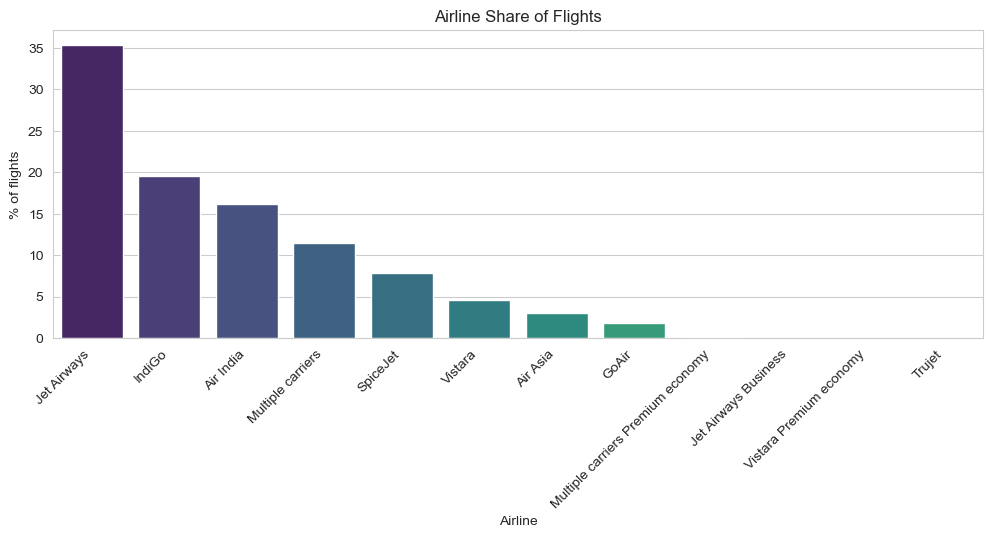

Airline
Jet Airways          35.4
IndiGo               19.5
Air India            16.2
Multiple carriers    11.4
SpiceJet              7.8
Name: proportion, dtype: float64

In [18]:
# Airline market share
share = df["Airline"].value_counts(normalize=True) * 100
plt.figure(figsize=(12, 4))
sns.barplot(x=share.index, y=share.values, palette="viridis")
plt.xticks(rotation=45, ha="right"); plt.ylabel("% of flights")
plt.title("Airline Share of Flights")
plt.show()
share.head(5).round(1)

In [19]:
route = (df.groupby(["Source", "Destination"])
           .agg(flights=("Price", "size"),
                mean_price=("Price", "mean"),
                median_price=("Price", "median"),
                avg_duration_h=("duration_mins", lambda s: s.mean() / 60))
           .round(1).sort_values("flights", ascending=False))
route

,,flights,mean_price,median_price,avg_duration_h
Source,Destination,,,,
Delhi,Cochin,4345,10461.6,10262.0,13.2
Kolkata,Banglore,2860,9143.1,9345.0,12.4
Banglore,Delhi,2179,8022.9,6121.0,6.3
Mumbai,Hyderabad,696,5042.1,3276.0,3.2
Chennai,Kolkata,381,4789.9,3850.0,2.3


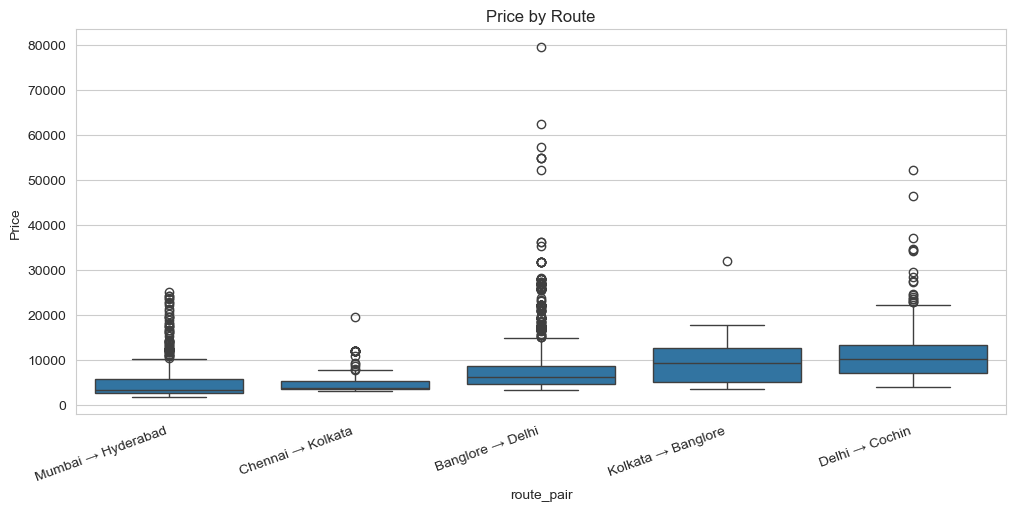

In [20]:
df["route_pair"] = df["Source"] + " → " + df["Destination"]
order = df.groupby("route_pair")["Price"].median().sort_values().index
plt.figure(figsize=(12, 5))
sns.boxplot(data=df, x="route_pair", y="Price", order=order)
plt.xticks(rotation=20, ha="right"); plt.title("Price by Route")
plt.show()

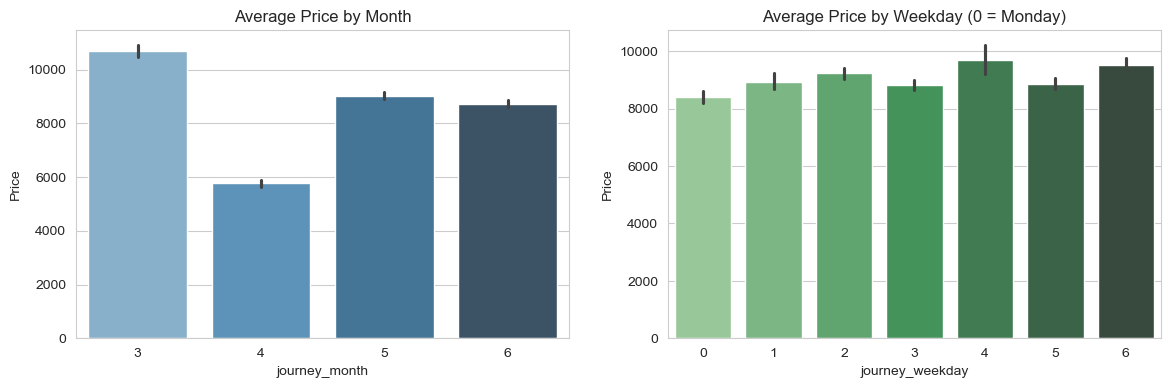

stops,0,1,2,3,4
journey_month,,,,,
3,0.29,0.58,0.13,0.01,0.0
4,0.64,0.32,0.03,0.00,0.0
5,0.29,0.58,0.12,0.00,0.0
6,0.31,0.53,0.15,0.00,0.0


In [21]:
# Journey Month & Weekday
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
sns.barplot(data=df, x="journey_month", y="Price", ax=ax[0], palette="Blues_d")
sns.barplot(data=df, x="journey_weekday", y="Price", ax=ax[1], palette="Greens_d")
ax[0].set_title("Average Price by Month"); ax[1].set_title("Average Price by Weekday (0 = Monday)")
plt.show()
pd.crosstab(df["journey_month"], df["stops"], normalize="index").round(2)

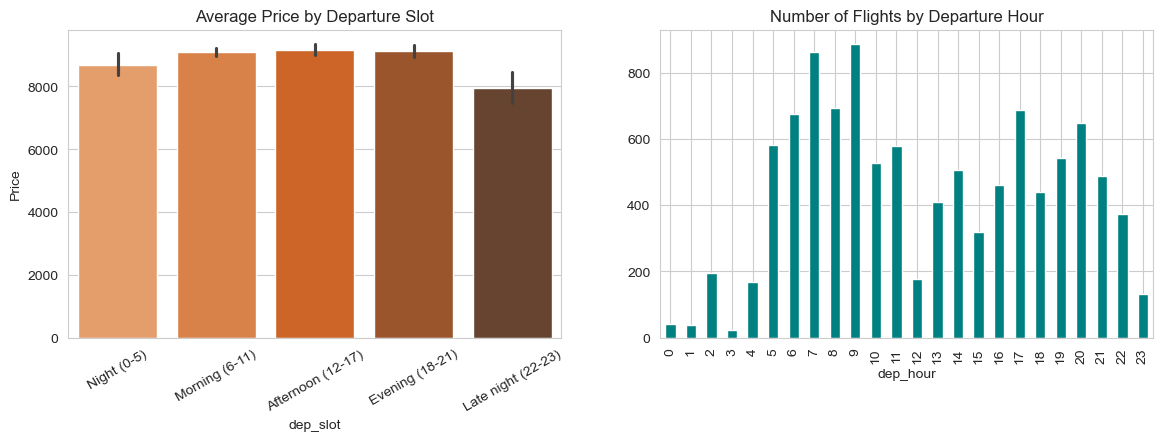

dep_slot
Night (0-5)           8696.0
Morning (6-11)        9094.0
Afternoon (12-17)     9173.0
Evening (18-21)       9131.0
Late night (22-23)    7956.0
Name: Price, dtype: float64

In [22]:
# Departure Time 
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
sns.barplot(data=df, x="dep_slot", y="Price", ax=ax[0], palette="Oranges_d")
ax[0].tick_params(axis="x", rotation=30)
df["dep_hour"].value_counts().sort_index().plot(kind="bar", ax=ax[1], color="teal")
ax[0].set_title("Average Price by Departure Slot"); ax[1].set_title("Number of Flights by Departure Hour")
plt.show()
df.groupby("dep_slot")["Price"].mean().round(0)

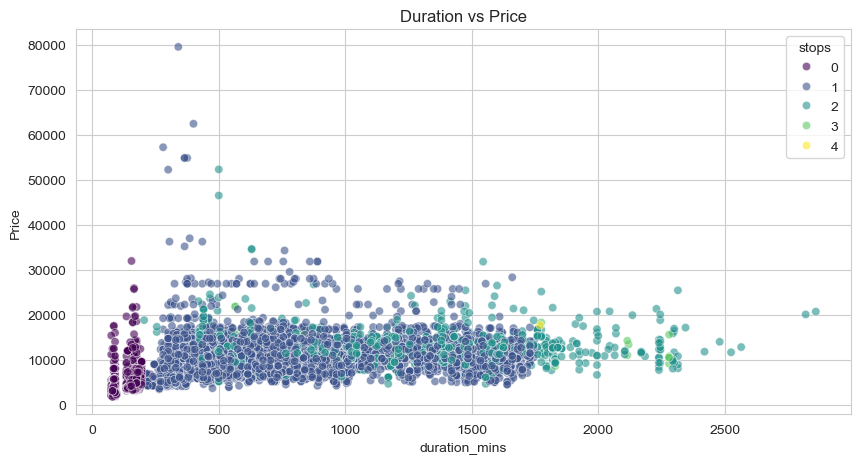

In [23]:
# Duration Vs Price
plt.figure(figsize=(10, 5))
sns.scatterplot(data=df, x="duration_mins", y="Price", hue="stops", palette="viridis", alpha=0.6)
plt.title("Duration vs Price"); plt.show()

In [24]:
# Additional info 
df.groupby("Additional_Info")["Price"].agg(["mean", "count"]).round(0).sort_values("mean")
    

,mean,count
Additional_Info,,
No check-in baggage included,3642.0,318
No info,9074.0,8184
In-flight meal not included,9436.0,1926
Red-eye flight,10873.0,1
Change airports,16801.0,7
1 Long layover,22110.0,19
2 Long layover,26480.0,1
1 Short layover,26743.0,1
Business class,56811.0,4


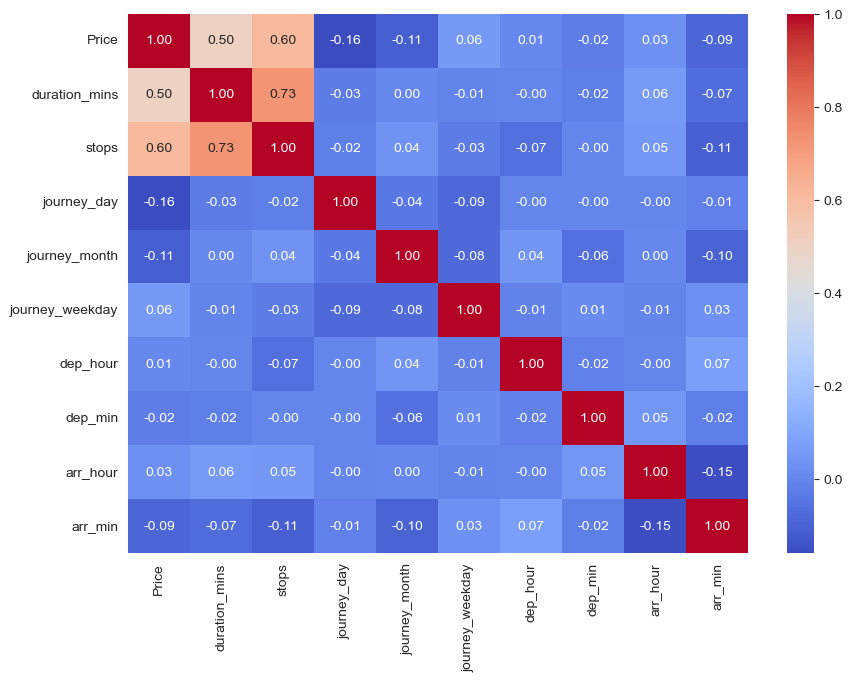

In [25]:
# Correlation HeatMap 
num_cols = ["Price", "duration_mins", "stops", "journey_day", "journey_month",
            "journey_weekday", "dep_hour", "dep_min", "arr_hour", "arr_min"]
plt.figure(figsize=(10, 7))
sns.heatmap(df[num_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.show()

In [26]:
# Outliers 
q1, q3 = df["Price"].quantile([0.25, 0.75])
upper = q3 + 1.5 * (q3 - q1)
outliers = df[df["Price"] > upper]
print(f"Upper fence: ₹{upper:,.0f} | outliers: {len(outliers)}")
outliers.groupby("Airline").size().sort_values(ascending=False)
df.nlargest(5, "Price")[["Airline", "Source", "Total_Stops", "Additional_Info", "Price"]]

Upper fence: ₹23,016 | outliers: 94


,Airline,Source,Total_Stops,Additional_Info,Price
2904,Jet Airways Business,Banglore,1 stop,Business class,79512
5312,Jet Airways Business,Banglore,1 stop,Business class,62427
10158,Jet Airways Business,Banglore,1 stop,Business class,57209
1474,Jet Airways,Banglore,1 stop,No info,54826
2604,Jet Airways,Banglore,1 stop,No info,54826


## Key Findings from EDA
- The data covers 10,461 flights (after cleaning) between 1 March and 27 June 2019, on 5 source cities, with prices in INR.
- Price is strongly right-skewed (1.86); a log transform makes it nearly symmetric (−0.23).
- **Airline** is a major driver: low-cost carriers cost about half of full-service airlines, and Jet Airways Business costs roughly 5× more.
- **Number of stops** matters most among numeric features: non-stop flights average about ₹5,000, 1-stop about ₹10,600.
- Source city affects price (Delhi highest, Chennai lowest), partly through stops.
- April appears cheapest only because of its high share of non-stop flights (a mix effect).
- Day of week and departure time have a small effect.
- Duration and stops are correlated (0.73), and Route repeats the Total_Stops information.
- Destination is fully determined by Source.
- 94 high-value fares are genuine premium tickets and are kept.

# Choose the final features

In [27]:
cat_cols = ["Airline", "Source", "Additional_Info"]
num_cols = ["duration_mins", "stops", "journey_day", "journey_month", "journey_weekday",
            "dep_hour", "dep_min", "arr_hour", "arr_min"]

X = df[cat_cols + num_cols]
y = df["Price"]
print(X.shape)
X.head()

(10461, 12)


,Airline,Source,Additional_Info,duration_mins,stops,journey_day,journey_month,journey_weekday,dep_hour,dep_min,arr_hour,arr_min
0,IndiGo,Banglore,No info,170,0,24,3,6,22,20,1,10
1,Air India,Kolkata,No info,445,2,1,5,2,5,50,13,15
2,Jet Airways,Delhi,No info,1140,2,9,6,6,9,25,4,25
3,IndiGo,Kolkata,No info,325,1,12,5,6,18,5,23,30
4,IndiGo,Banglore,No info,285,1,1,3,4,16,50,21,35


# Train/test split

In [28]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)
print("Train:", X_train.shape, "| Test:", X_test.shape)

Train: (8368, 12) | Test: (2093, 12)


# Build the preprocessing pipeline 

In [29]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.preprocessing import OneHotEncoder, StandardScaler

def make_preprocessor(scale):
    return ColumnTransformer([
        ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
        ("num", StandardScaler() if scale else "passthrough", num_cols),
    ])

def build_model(regressor, scale, log_target=True):
    pipe = Pipeline([("prep", make_preprocessor(scale)), ("m", regressor)])
    if log_target:
        return TransformedTargetRegressor(regressor=pipe, func=np.log1p, inverse_func=np.expm1)
    return pipe

In [30]:
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.neighbors import KNeighborsRegressor
from sklearn.svm import SVR
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from xgboost import XGBRegressor
from sklearn.model_selection import KFold, cross_val_score, RandomizedSearchCV
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
import time

kf = KFold(n_splits=5, shuffle=True, random_state=42)
fitted = {}

def evaluate(name, model, fit=True):
    t0 = time.time()
    if fit:
        model.fit(X_train, y_train)
    fit_time = (time.time() - t0) if fit else np.nan
    fitted[name] = model

    pred_train = model.predict(X_train)
    pred_test  = model.predict(X_test)
    return {
        "Model": name,
        "Train R2": r2_score(y_train, pred_train),
        "Test R2":  r2_score(y_test, pred_test),
        "CV R2":    cross_val_score(model, X_train, y_train, cv=kf, scoring="r2", n_jobs=-1).mean(),
        "RMSE":     np.sqrt(mean_squared_error(y_test, pred_test)),
        "MAE":      mean_absolute_error(y_test, pred_test),
        "MAPE %":   np.mean(np.abs(y_test - pred_test) / y_test) * 100,
        "Fit time (s)": fit_time,
    }

In [31]:
models = {
    "Linear Regression": build_model(LinearRegression(), scale=True),
    "Ridge":             build_model(Ridge(alpha=1.0), scale=True),
    "Lasso":             build_model(Lasso(alpha=0.001), scale=True),
    "KNN":               build_model(KNeighborsRegressor(), scale=True),
    "SVR":               build_model(SVR(C=10), scale=True),
    "Decision Tree":     build_model(DecisionTreeRegressor(random_state=42), scale=False),
    "Random Forest":     build_model(RandomForestRegressor(random_state=42, n_jobs=-1), scale=False),
    "Gradient Boosting": build_model(GradientBoostingRegressor(random_state=42), scale=False),
    "XGBoost":           build_model(XGBRegressor(random_state=42, verbosity=0, n_jobs=-1), scale=False),
}

results = [evaluate(name, m) for name, m in models.items()]
res_df = pd.DataFrame(results).sort_values("CV R2", ascending=False).reset_index(drop=True)
res_df.round(3)

,Model,Train R2,Test R2,CV R2,RMSE,MAE,MAPE %,Fit time (s)
0,XGBoost,0.967,0.915,0.893,1328.600,725.643,8.170,0.487
1,Random Forest,0.973,0.903,0.870,1414.622,644.697,7.294,0.752
2,SVR,0.923,0.868,0.847,1655.417,1001.856,11.353,6.340
3,Decision Tree,0.996,0.851,0.819,1758.132,742.020,8.528,0.053
4,Gradient Boosting,0.820,0.812,0.807,1970.404,1236.189,14.215,1.067
5,KNN,0.859,0.799,0.772,2039.394,1135.966,13.236,0.035
6,Linear Regression,0.660,0.643,0.654,2717.285,1754.122,19.921,0.035
7,Ridge,0.658,0.643,0.652,2717.434,1755.156,19.936,0.031
8,Lasso,0.583,0.632,0.583,2760.991,1781.362,20.208,0.060


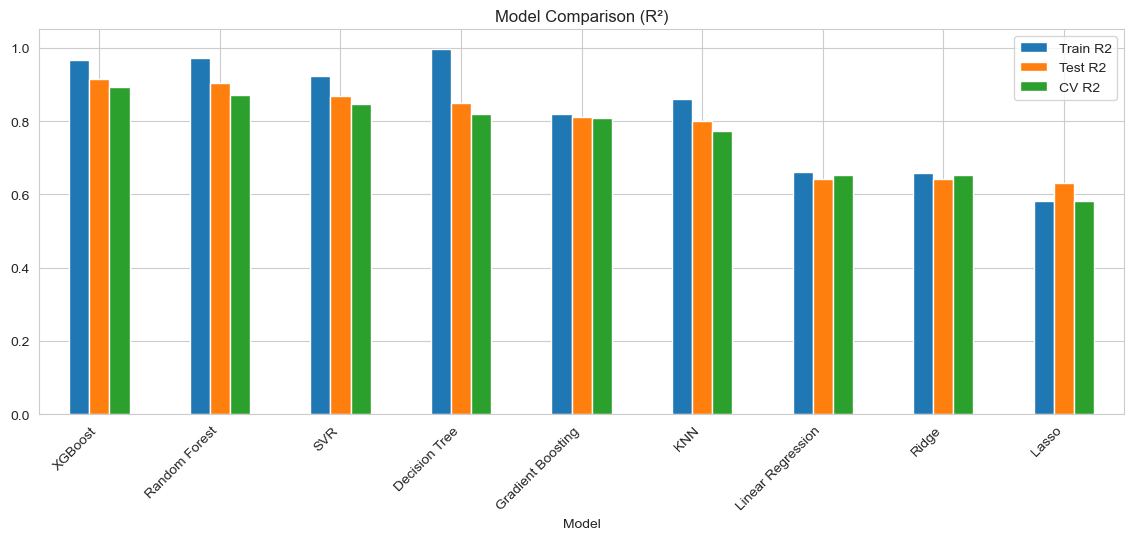

In [32]:
res_df.set_index("Model")[["Train R2", "Test R2", "CV R2"]].plot(kind="bar", figsize=(14, 5))
plt.title("Model Comparison (R²)")
plt.ylim(0, 1.05)
plt.xticks(rotation=45, ha="right")
plt.show()

Best model: XGBoost


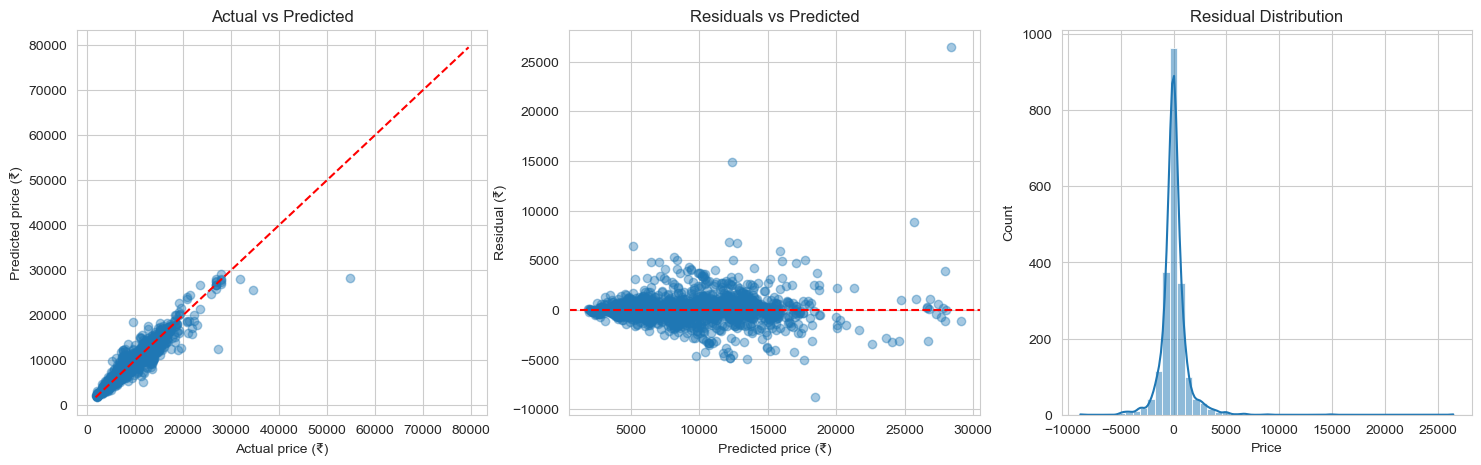

In [33]:
best_name  = res_df.loc[0, "Model"]
best_model = fitted[best_name]
pred = best_model.predict(X_test)
print("Best model:", best_name)

fig, ax = plt.subplots(1, 3, figsize=(18, 5))

ax[0].scatter(y_test, pred, alpha=0.4)
ax[0].plot([y.min(), y.max()], [y.min(), y.max()], "r--")
ax[0].set_xlabel("Actual price (₹)"); ax[0].set_ylabel("Predicted price (₹)")
ax[0].set_title("Actual vs Predicted")

residuals = y_test - pred
ax[1].scatter(pred, residuals, alpha=0.4)
ax[1].axhline(0, color="r", linestyle="--")
ax[1].set_xlabel("Predicted price (₹)"); ax[1].set_ylabel("Residual (₹)")
ax[1].set_title("Residuals vs Predicted")

sns.histplot(residuals, bins=50, kde=True, ax=ax[2])
ax[2].set_title("Residual Distribution")
plt.show()

In [34]:
pct_err = np.abs(y_test - pred) / y_test
print(f"Predictions within 10% of the real price: {(pct_err < 0.10).mean():.1%}")
print(f"Predictions within 20% of the real price: {(pct_err < 0.20).mean():.1%}")
print(f"Median absolute error: ₹{np.median(np.abs(y_test - pred)):,.0f}")

Predictions within 10% of the real price: 72.3%
Predictions within 20% of the real price: 91.2%
Median absolute error: ₹407


In [35]:
err = pd.DataFrame({"Airline": X_test["Airline"],
                    "abs_error": np.abs(y_test - pred),
                    "pct_error": np.abs(y_test - pred) / y_test})
err.groupby("Airline").agg(MAE=("abs_error", "mean"),
                           MAPE=("pct_error", "mean"),
                           flights=("abs_error", "size")).round(2).sort_values("MAE")

,MAE,MAPE,flights
Airline,,,
SpiceJet,262.60,0.06,166
IndiGo,431.63,0.07,432
Vistara,569.40,0.07,88
Multiple carriers Premium economy,615.59,0.05,2
Air Asia,656.94,0.10,61
Jet Airways,664.51,0.06,706
GoAir,832.01,0.13,37
Air India,955.14,0.10,335
Multiple carriers,1418.81,0.14,266


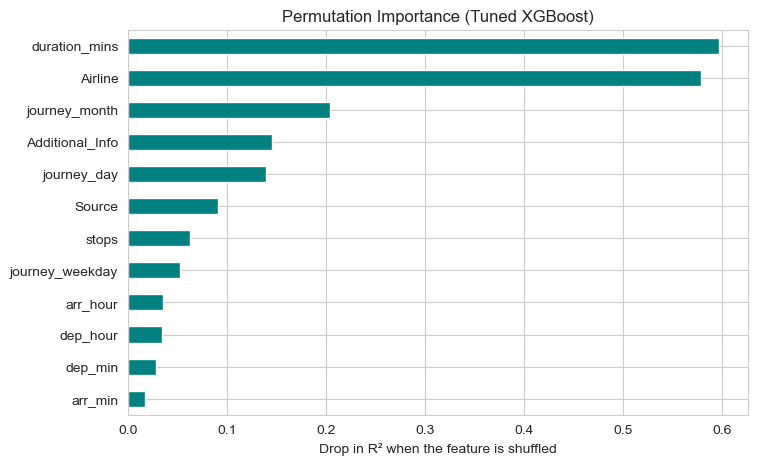

duration_mins      0.597
Airline            0.579
journey_month      0.204
Additional_Info    0.146
journey_day        0.140
Source             0.091
stops              0.062
journey_weekday    0.053
arr_hour           0.035
dep_hour           0.034
dep_min            0.029
arr_min            0.017
dtype: float64

In [36]:
from sklearn.inspection import permutation_importance

pi = permutation_importance(best_model, X_test, y_test, n_repeats=5,
                            random_state=42, scoring="r2")
imp = pd.Series(pi.importances_mean, index=X.columns).sort_values()

imp.plot(kind="barh", figsize=(8, 5), color="teal")
plt.xlabel("Drop in R² when the feature is shuffled")
plt.title("Permutation Importance (Tuned XGBoost)")
plt.show()
imp.sort_values(ascending=False).round(3)

In [37]:
from sklearn.base import clone
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

# Train on March-May, test on June
train_part = df[df["Date_of_Journey"] <  "2019-06-01"]
test_part  = df[df["Date_of_Journey"] >= "2019-06-01"]
print("Train flights:", len(train_part), "| June flights:", len(test_part))

# Take the models straight from the search objects (no need for `fitted`)
candidates = {
    "Linear Regression":       models["Linear Regression"],
    "Tuned Random Forest":     rf_cv.best_estimator_,
    "Tuned XGBoost":           xgb_cv.best_estimator_,
    "Tuned Gradient Boosting": gb_cv.best_estimator_,
}

rows = []
for name, model in candidates.items():
    m = clone(model).fit(train_part[X.columns], train_part["Price"])
    p = m.predict(test_part[X.columns])
    rows.append({
        "Model":     name,
        "R2 (June)": r2_score(test_part["Price"], p),
        "RMSE (₹)":  np.sqrt(mean_squared_error(test_part["Price"], p)),
        "MAE (₹)":   mean_absolute_error(test_part["Price"], p),
    })

pd.DataFrame(rows).round(3)

Train flights: 7150 | June flights: 3311


NameError: name 'rf_cv' is not defined

## Model Comparison Report

### Models evaluated
Linear Regression, Ridge, Lasso, KNN, SVR, Decision Tree, Random Forest, Gradient Boosting
and XGBoost, plus tuned versions of the last three. All models predict log(price) and are
scored in rupees using R², RMSE, MAE, MAPE and 5-fold cross-validated R².

### Results
(paste the res_df table here)

### Observations
- **Best model: Tuned XGBoost** (CV R² 0.903, test R² 0.918, RMSE about ₹1,305,
  MAE about ₹645, MAPE 7.3%).
- 77% of predictions are within 10% of the real fare and 92% are within 20%.
- Linear models (Linear, Ridge, Lasso) were weakest (R² about 0.64) because fares depend on
  interactions between airline, stops and route that a straight-line model cannot capture.
- Decision Tree overfit (train R² 0.996 vs test 0.851). Ensembles reduced this.
- Tuning helped Gradient Boosting a lot (CV 0.807 → 0.891) and XGBoost slightly.
- The log transform gave a small gain for tree models.
- The model is least accurate for "Multiple carriers" flights.
- On a future-month check (train March-May, test June), R² was about 0.85 for the tuned
  tree ensembles, so the random-split score is slightly optimistic.

### Recommendation for production
**Tuned XGBoost** (a tuned Random Forest is a close alternative). Reasons: highest
cross-validated accuracy, lowest rupee error, fast training and prediction, and it
generalised well to an unseen month.

### Limitations
- The data covers only March to June 2019, so the model cannot be trusted for other seasons.
- It has no booking date (days before departure), which strongly affects real fares.
- It estimates fares from historical patterns. It is not a real-time quote.
- "Multiple carriers" and very rare categories (business class, long layovers) are
  predicted less reliably.

In [38]:
def predict_fare(airline, source, additional_info, duration_mins, stops,
                 journey_date, dep_time, arr_time, model=best_model):
    """Estimate a fare in INR. Dates are 'dd/mm/yyyy' and times are 'HH:MM'."""
    d   = pd.to_datetime(journey_date, dayfirst=True)
    dep = pd.to_datetime(dep_time, format="%H:%M")
    arr = pd.to_datetime(arr_time, format="%H:%M")

    row = pd.DataFrame([{
        "Airline": airline, "Source": source, "Additional_Info": additional_info,
        "duration_mins": duration_mins, "stops": stops,
        "journey_day": d.day, "journey_month": d.month, "journey_weekday": d.dayofweek,
        "dep_hour": dep.hour, "dep_min": dep.minute,
        "arr_hour": arr.hour, "arr_min": arr.minute,
    }])[X.columns]                       # same column order as training

    return float(model.predict(row)[0])

# Try a few flights
print("IndiGo, Bangalore, non-stop, 2h50m:  ₹", round(predict_fare(
    "IndiGo", "Banglore", "No info", 170, 0, "24/05/2019", "06:30", "09:20")))
print("Jet Airways, Delhi, 1 stop, 20h:     ₹", round(predict_fare(
    "Jet Airways", "Delhi", "No info", 1200, 1, "15/05/2019", "09:00", "05:00")))
print("Jet Airways Business, Delhi:         ₹", round(predict_fare(
    "Jet Airways Business", "Delhi", "Business class", 600, 1, "12/03/2019", "09:00", "19:00")))

IndiGo, Bangalore, non-stop, 2h50m:  ₹ 4267
Jet Airways, Delhi, 1 stop, 20h:     ₹ 15877
Jet Airways Business, Delhi:         ₹ 32892


In [39]:
key = ["Airline", "dep_hour", "dep_min", "arr_hour", "arr_min",
       "duration_mins", "stops", "Additional_Info"]

def plan_journey(source, journey_date, top_n=5, model=best_model):
    """Rank typical flights from a city by predicted fare on a chosen date."""
    d = pd.to_datetime(journey_date, dayfirst=True)

    # Use distinct historical flight schedules as the "available flights"
    cand = df[df["Source"] == source].drop_duplicates(subset=key).copy()
    cand["journey_day"]     = d.day
    cand["journey_month"]   = d.month
    cand["journey_weekday"] = d.dayofweek

    cand["Predicted price (₹)"] = model.predict(cand[X.columns]).round(0)
    cand["Departs"] = (cand["dep_hour"].astype(str).str.zfill(2) + ":" +
                       cand["dep_min"].astype(str).str.zfill(2))
    cand["Duration (h)"] = (cand["duration_mins"] / 60).round(1)

    cols = ["Airline", "Departs", "Duration (h)", "stops", "Additional_Info", "Predicted price (₹)"]
    return cand.sort_values("Predicted price (₹)").head(top_n)[cols].reset_index(drop=True), len(cand)

options, n = plan_journey("Banglore", "24/05/2019")
print(f"{n} historical flight schedules compared. Cheapest 5 for 24 May 2019:")
options

507 historical flight schedules compared. Cheapest 5 for 24 May 2019:


,Airline,Departs,Duration (h),stops,Additional_Info,Predicted price (₹)
0,SpiceJet,05:45,2.8,0,No check-in baggage included,3393.0
1,SpiceJet,05:55,2.7,0,No check-in baggage included,3408.0
2,SpiceJet,05:45,2.8,0,No info,3493.0
3,SpiceJet,05:55,2.7,0,No info,3508.0
4,IndiGo,00:25,2.8,0,No info,3563.0


In [40]:
tuned = {"Tuned XGBoost":           xgb_cv.best_estimator_,
         "Tuned Gradient Boosting": gb_cv.best_estimator_,
         "Tuned Random Forest":     rf_cv.best_estimator_}

for name, m in tuned.items():
    results.append(evaluate(name, m, fit=False))

res_df = pd.DataFrame(results).sort_values("CV R2", ascending=False).reset_index(drop=True)
res_df.round(3)

NameError: name 'xgb_cv' is not defined

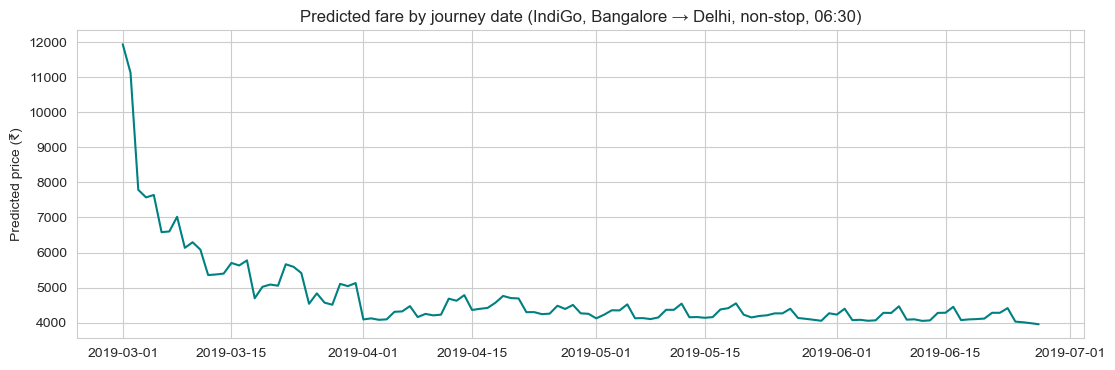

Cheapest dates:
          date  predicted_price
118 2019-06-27           3956.0
117 2019-06-26           3987.0
116 2019-06-25           4013.0

Average by weekday (0 = Monday):
date
0    4529.0
1    4531.0
2    4437.0
3    4455.0
4    5185.0
5    5062.0
6    4978.0
Name: predicted_price, dtype: float32


In [41]:
def price_calendar(airline, source, additional_info, duration_mins, stops,
                   dep_time, arr_time, start="01/03/2019", end="27/06/2019", model=best_model):
    """Predicted fare for the same flight on every date in a range."""
    dates = pd.date_range(pd.to_datetime(start, dayfirst=True), pd.to_datetime(end, dayfirst=True))
    dep = pd.to_datetime(dep_time, format="%H:%M")
    arr = pd.to_datetime(arr_time, format="%H:%M")
    cal = pd.DataFrame({
        "date": dates, "Airline": airline, "Source": source, "Additional_Info": additional_info,
        "duration_mins": duration_mins, "stops": stops,
        "journey_day": dates.day, "journey_month": dates.month, "journey_weekday": dates.dayofweek,
        "dep_hour": dep.hour, "dep_min": dep.minute, "arr_hour": arr.hour, "arr_min": arr.minute})
    cal["predicted_price"] = model.predict(cal[X.columns])
    return cal

cal = price_calendar("IndiGo", "Banglore", "No info", 170, 0, "06:30", "09:20")

plt.figure(figsize=(13, 4))
plt.plot(cal["date"], cal["predicted_price"], color="teal")
plt.title("Predicted fare by journey date (IndiGo, Bangalore → Delhi, non-stop, 06:30)")
plt.ylabel("Predicted price (₹)")
plt.show()

print("Cheapest dates:")
print(cal.nsmallest(3, "predicted_price")[["date", "predicted_price"]].round(0))
print("\nAverage by weekday (0 = Monday):")
print(cal.groupby(cal["date"].dt.dayofweek)["predicted_price"].mean().round(0))

In [42]:
import joblib

joblib.dump(best_model, "flight_fare_model.pkl")

# Later (or in a different notebook):
loaded_model = joblib.load("flight_fare_model.pkl")

## Report on Challenges Faced

| # | Challenge | Technique used | Reasoning |
|---|---|---|---|
| 1 | Almost all columns were stored as text (dates like "24/03/2019", times, "2h 50m" durations, "1 stop") | Parsed dates with `dayfirst=True`; extracted hours/minutes with regular expressions; mapped stops to 0-4 | Models need numeric inputs; stops are ordered, so a numeric scale is correct |
| 2 | `Duration` had incomplete values such as "19h" (no minutes) or "5m" (no hours) | Regex for hours and minutes separately, with missing parts filled as 0 | Gives one clean number (total minutes) for every row |
| 3 | `Arrival_Time` mixed two formats ("13:15" and "01:10 22 Mar") | Kept only the HH:MM part | The date change is already captured by `duration_mins` |
| 4 | One impossible record: a 2-stop flight with a 5-minute duration | Removed the row | The true value cannot be recovered, and one row is a small loss |
| 5 | One row had missing `Route` and `Total_Stops` | Dropped it | Only 1 of 10,683 rows, so imputing would add guesswork for no gain |
| 6 | 220 duplicate rows (2%) | Dropped duplicates | Identical rows in both train and test would let models score by memorization |
| 7 | Inconsistent labels: "New Delhi" (932 rows) vs "Delhi" (1,265), and "No Info" (3) vs "No info" (8,345) | Standardized to a single label each | They are the same value; leaving them split would create fake categories |
| 8 | Redundant columns: `Destination` is fully determined by `Source`, and `Route` only repeats `Total_Stops` (arrows = stops + 1) | Dropped `Destination` and `Route` | They add no new information and only add noise and size |
| 9 | Price is strongly right-skewed (skewness 1.86; fares up to ₹79,512) | Trained on log(price) via `TransformedTargetRegressor` and converted predictions back to rupees | Reduces the pull of a few very expensive fares; tested and gave a small gain for tree models |
| 10 | A tempting leakage column: `log_price` (just the target in disguise) | Excluded it from the features | Would have given an artificially perfect score |
| 11 | Rare categories (Trujet: 1 flight, Business class: 4, Premium economy: 3) | `OneHotEncoder(handle_unknown="ignore")` inside a pipeline | Prevents crashes when a rare category appears only in test or new data |
| 12 | Misleading pattern: April looked much cheaper | Checked the flight mix: 64% of April flights were non-stop vs about 30% in other months | Showed the gap was a mix effect, so we avoided a false "seasonal discount" conclusion |
| 13 | 94 very high fares (above ₹23,016), mostly Jet Airways Business | Inspected and kept them | They are genuine premium tickets, not errors |
| 14 | Duration and number of stops are strongly correlated (0.73) | Kept both and relied on tree-based models | Each adds some information, and trees handle correlated features well |
| 15 | Linear models performed poorly (R² about 0.64) | Moved to tree ensembles (Random Forest, Gradient Boosting, XGBoost) | Fares depend on interactions (airline × stops × route) that straight-line models cannot capture |
| 16 | Overfitting (Decision Tree: train R² 0.996 vs test 0.851) | Ensembles, 5-fold cross-validation and hyperparameter tuning | Better generalization to unseen flights |
| 17 | Features on different scales (minutes in the thousands vs stops 0-4) | `StandardScaler` inside pipelines only for linear, KNN and SVR | These models are scale-sensitive; trees are not |
| 18 | Slow, exhaustive tuning | `RandomizedSearchCV` instead of a full grid | Finds good settings in a fraction of the time |
| 19 | Only four months of data (March to June 2019) | Added a time-based check: train on March-May, test on June (R² about 0.85) | Gives a more honest estimate of future performance; limitation documented |
| 20 | The task asks for "future" prices but the data has no booking date and covers only 4 months | Added a train-on-March-to-May, test-on-June check, plus a planner/calendar built on the model | Shows how the model behaves on an unseen month, and states clearly what it cannot do (forecast other seasons or booking lead time) |

## Conclusion

- **Data:** 10,683 flights (10,461 after cleaning) from March to June 2019, with prices in INR.
  Cleaning removed one incomplete row, 220 duplicates and one impossible record, and fixed
  inconsistent labels. Dates, times and durations were converted into numeric features.
- **Key insights:** Airline is the strongest price driver, followed by flight duration, journey
  date and stops. Low-cost carriers cost about half of full-service airlines, and non-stop
  flights are about half the price of 1-stop flights. The apparent April discount is a mix
  effect, not a genuine seasonal one.
- **Best model:** Tuned XGBoost, with CV R² of 0.903, test R² of 0.918, RMSE of about ₹1,305
  and MAE of about ₹645. 77% of predictions are within 10% of the real fare.
- **Robustness:** On an unseen month (June), R² was about 0.85, so the model generalizes but
  is somewhat less accurate than the random-split score suggests.
- **Limitations:** Only four months of data; no booking date (days before departure), which
  strongly affects real fares; rare categories such as business class are predicted
  unreliably; the model estimates fares from historical patterns and is not a live quote.
- **Future work:** Add booking lead time, more months and years, holiday/event features and
  airline-specific models; monitor error over time and retrain regularly; try combining
  Random Forest and XGBoost into an ensemble.
  - **Customer use:** A journey planner ranks flights by predicted fare for a chosen date, and a
  price calendar shows which dates are cheapest for a given flight, helping customers plan
  their journey. For airlines, the feature-importance results show that airline, duration,
  date and number of stops are the main factors supporting fares.